# Сети Колмогорова–Арнольда на двух простых примерах

*Учебное приложение к главе 4 пособия «Нейронные сети для инженеров»*

В этом блокноте сравниваются две ситуации:

| | Пример 1 | Пример 2 |
|---|---|---|
| Функция | $f(x)=a\cos x+b$ | $f(x,y)=\exp(\sin\pi x+y^2)$ |
| Архитектура | KAN 1–1 | KAN 2–1–1 |
| Чему учит | сеть с одной связью — это обычный МНК | польза сети начинается с композиции функций |

Для каждого примера мы обучим сеть, посмотрим, какие функции она выучила, восстановим формулу (*символизация*) и проверим, как модели ведут себя **за пределами** области обучения.

**Как запустить.** Блокнот должен лежать в одной папке с модулем `kan.py` из цифрового Приложения 2: оттуда берутся B-сплайны, слой сети, обучение методом Adam. Нужны только NumPy и Matplotlib. Полный прогон занимает около минуты.

**Содержание**
1. [Подготовка](#prep)
2. [Пример 1. $a\cos x+b$: когда KAN сводится к МНК](#ex1)
3. [Пример 2. $\exp(\sin\pi x+y^2)$: когда нужны KAN и итерации](#ex2)
4. [Итог: что даёт сеть, а что — формула](#summary)

<a id="prep"></a>
## 1. Подготовка

Напомним, как устроена функция на связи сети Колмогорова–Арнольда (формула (4.19) главы):

$$
\phi(x)=w_b\,\mathrm{SiLU}(x)+w_s\sum_{m=0}^{G+k-1}c_m B_{m,k}(x),
\qquad \mathrm{SiLU}(x)=\frac{x}{1+e^{-x}},
$$

где $B_{m,k}$ — B-сплайны степени $k$ на сетке из $G$ интервалов, $c_m$ — их коэффициенты, $w_b$ и $w_s$ — веса базовой и сплайновой частей. Узел сети только суммирует значения функций на входящих связях.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LogNorm
from matplotlib.patches import Circle, Rectangle, FancyArrowPatch, FancyBboxPatch
from IPython.display import Markdown, display

from kan import KAN, train, bspline, knots, silu   # реализация сети: модуль kan.py

# Оформление рисунков как в пособии: чёрно-белые, шрифты STIX, десятичная запятая
plt.rcParams.update({'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix', 'font.size': 10,
                     'axes.linewidth': 0.7, 'legend.frameon': False, 'figure.dpi': 110})
_sf = mticker.ScalarFormatter.__call__
mticker.ScalarFormatter.__call__ = lambda self, x, pos=None: _sf(self, x, pos).replace('.', ',')
GREY = '0.92'

rmse = lambda p, y: float(np.sqrt(np.mean((p - y) ** 2)))
num = lambda v, d=4: f'{v:.{d}g}'.replace('.', ',')          # для текста
mnum = lambda v, d=4: f'{v:.{d}g}'.replace('.', '{,}')      # для формул (без пробела после запятой)
fx = lambda v: f'{v:.4f}'.replace('.', ',')
pct = lambda v: (f'{v:.0f}' if v >= 10 else f'{v:.1f}').replace('.', ',') + ' %'

In [2]:
# ---------- символизация: библиотека элементарных функций ----------
# Для каждой функции g подбирается alpha*g(beta*z + gamma) + eta:
# beta и gamma — перебором по сетке, alpha и eta — линейным МНК.
LIB = {
    'z':          (lambda z, b, g: z,               [1.0],                      [0.0]),
    'z²':         (lambda z, b, g: z ** 2,          [1.0],                      [0.0]),
    'z³':         (lambda z, b, g: z ** 3,          [1.0],                      [0.0]),
    'tanh(βz)':   (lambda z, b, g: np.tanh(b * z),  np.linspace(0.2, 5, 97),    [0.0]),
    'exp(βz)':    (lambda z, b, g: np.exp(b * z),   np.linspace(-5, 5, 1001),   [0.0]),
    'sin(βz+γ)':  (lambda z, b, g: np.sin(b * z + g), np.linspace(0.2, 6, 117), np.linspace(-np.pi, np.pi, 73)),
}
COMPLEXITY = {'z': 0, 'z²': 0, 'z³': 0, 'tanh(βz)': 1, 'exp(βz)': 1, 'sin(βz+γ)': 2}   # число нелинейных параметров

def symbolize(z, phi):
    table = {}
    for name, (g, betas, gammas) in LIB.items():
        best = (-np.inf, None)
        for b in betas:
            for gm in gammas:
                A = np.stack([g(z, b, gm), np.ones_like(z)], axis=1)
                coef = np.linalg.lstsq(A, phi, rcond=None)[0]
                r2 = 1 - np.sum((A @ coef - phi) ** 2) / np.sum((phi - phi.mean()) ** 2)
                if r2 > best[0]:
                    best = (r2, [coef[0], b, gm, coef[1]])
        # уточнение: более мелкая сетка вокруг найденных beta, gamma
        if len(betas) > 1:
            db = betas[1] - betas[0]
            dg = gammas[1] - gammas[0] if len(gammas) > 1 else 0.0
            b0, g0 = best[1][1], best[1][2]
            for b in np.linspace(b0 - db, b0 + db, 41):
                for gm in (np.linspace(g0 - dg, g0 + dg, 41) if dg else [g0]):
                    A = np.stack([g(z, b, gm), np.ones_like(z)], axis=1)
                    coef = np.linalg.lstsq(A, phi, rcond=None)[0]
                    r2 = 1 - np.sum((A @ coef - phi) ** 2) / np.sum((phi - phi.mean()) ** 2)
                    if r2 > best[0]:
                        best = (r2, [coef[0], b, gm, coef[1]])
        r2, (al, b, gm, et) = best
        if name.startswith('sin') and al < 0:                 # -sin(t) = sin(t + pi)
            al, gm = -al, (gm + 2 * np.pi) % (2 * np.pi) - np.pi
        table[name] = (r2, (al, b, gm, et))
    return table

def choose(table, tol=1e-4):
    # из функций с R² не хуже лучшего на tol выбирается самая простая
    top = max(v[0] for v in table.values())
    return min((n for n in table if table[n][0] >= top - tol), key=lambda n: (COMPLEXITY[n], -table[n][0]))

def r2_table(rows):
    # rows: {имя связи: таблица symbolize}; возвращает Markdown-таблицу с выделенным выбором
    head = '| Связь | ' + ' | '.join(LIB) + ' | выбрано |\n|' + '---|' * (len(LIB) + 2) + '\n'
    body = ''
    for ename, tab in rows.items():
        best = choose(tab)
        cells = [(f'**{tab[n][0]:.8f}**' if n == best else f'{tab[n][0]:.8f}').replace('.', ',') for n in LIB]
        body += f'| {ename} | ' + ' | '.join(cells) + f' | {best} |\n'
    return head + body

In [3]:
# ---------- рисование схемы сети ----------
def _arrow(ax, x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=9,
                                 lw=0.8, color='black', shrinkA=0, shrinkB=0))

def _node(ax, x, y, text, r=0.42):
    ax.add_patch(Circle((x, y), r, fc='white', ec='black', lw=0.9))
    ax.text(x, y, text, ha='center', va='center', fontsize=12)

def _edge(ax, cx, cy, z, phi, title, sym, w=3.0, h=2.0):
    ax.add_patch(Rectangle((cx - w / 2, cy - h / 2), w, h, fc=GREY, ec='black', lw=0.8))
    yn = (phi - phi.min()) / np.ptp(phi)
    ax.plot(cx - w / 2 + 0.2 + (z - z.min()) / np.ptp(z) * (w - 0.4), cy - h / 2 + 0.2 + yn * (h - 0.4), 'k-', lw=1.3)
    ax.text(cx, cy + h / 2 + 0.25, title, ha='center', fontsize=11)
    ax.text(cx, cy - h / 2 - 0.45, sym, ha='center', fontsize=10)

def signed(v, d=2):
    return ('+' if v >= 0 else '-') + mnum(abs(v), d)

<a id="ex1"></a>
## 2. Пример 1. $f(x)=a\cos x+b$: когда KAN сводится к МНК

Возьмём $a=2$, $b=0{,}5$. Сеть получает только 200 пар $(x,f(x))$ на отрезке $[-\pi,\pi]$; значений $a$ и $b$ она не знает. Вход нормируем на отрезок сетки: $\tilde x=x/\pi\in[-1,1]$.

Функция одной переменной, поэтому достаточно сети **1–1**: одна связь, одна обучаемая функция $\phi$, $G=5$, $k=3$, то есть $G+k+2=10$ параметров.

In [4]:
a_true, b_true = 2.0, 0.5
f1 = lambda x: a_true * np.cos(x) + b_true

rng = np.random.default_rng(7)
x_tr, x_va = rng.uniform(-np.pi, np.pi, 200), rng.uniform(-np.pi, np.pi, 50)
X_tr1, X_va1 = (x_tr / np.pi)[:, None], (x_va / np.pi)[:, None]
y_tr1, y_va1 = f1(x_tr)[:, None], f1(x_va)[:, None]

net1 = KAN([1, 1], G=5, k=3)
L = net1.layers[0]
L.c[...] = rng.normal(0, 0.1, L.c.shape)
L.wb[...] = rng.normal(0, 1.0, L.wb.shape)
hist1 = []
train(net1, X_tr1, y_tr1, X_va1, y_va1, epochs=3000, lr=0.01, history=hist1)

x_test = np.linspace(-np.pi, np.pi, 1001)
rmse_adam = rmse(net1.forward((x_test / np.pi)[:, None])[:, 0], f1(x_test))
print(f'KAN 1–1: {net1.n_params()} параметров, RMSE на [−π, π] = {rmse_adam:.2e}')

KAN 1–1: 10 параметров, RMSE на [−π, π] = 4.46e-03


### 2.1. Обучение этой сети — линейная задача МНК

Функция на связи $\phi(\tilde x)=w_b\,\mathrm{SiLU}(\tilde x)+w_s\sum_m c_mB_m(\tilde x)$ **линейна** по $w_b$ и по $c_m$ (множитель $w_s$ можно внести в $c_m$). Значит, вместо 3000 эпох метода Adam минимум MSE находится одной операцией метода наименьших квадратов $\mathbf c=V\backslash\mathbf y$, как в главе 3: столбцы матрицы $V$ — это $\mathrm{SiLU}(\tilde x)$ и $B_0(\tilde x),\ldots,B_7(\tilde x)$.

In [5]:
t1, k1 = L.t[0], L.k
V  = np.hstack([silu(X_tr1), bspline(X_tr1[:, 0], t1, k1)])
coef = np.linalg.lstsq(V, y_tr1[:, 0], rcond=None)[0]
xt = x_test / np.pi
rmse_lsq = rmse(np.hstack([silu(xt[:, None]), bspline(xt, t1, k1)]) @ coef, f1(x_test))

display(Markdown(rf'''
| Способ | Итераций | RMSE на $[-\pi,\pi]$ |
|---|---|---|
| Adam | 3000 | {num(rmse_adam, 3)} |
| прямой МНК $V\backslash y$ | 0 | {num(rmse_lsq, 3)} |
'''))


| Способ | Итераций | RMSE на $[-\pi,\pi]$ |
|---|---|---|
| Adam | 3000 | 0,00446 |
| прямой МНК $V\backslash y$ | 0 | 0,00336 |


Прямой МНК даже точнее: он сразу даёт точку минимума, к которой Adam только приближается. **Сеть 1–1 — это сплайновая регрессия из главы 3.** Итерации здесь не нужны.

### 2.2. Что выучила сеть

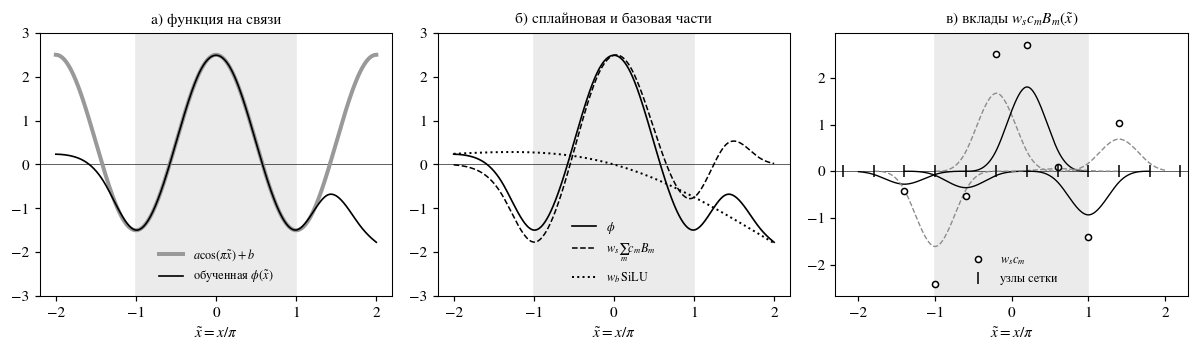

w_b = -1.019,  w_s = 2.252,  c_m = [-0.185 -1.074 -0.234  1.113  1.203  0.037 -0.623  0.459]


In [6]:
xx = np.linspace(-2, 2, 2001)
B = bspline(xx, t1, k1)
wb, ws, c = L.wb[0, 0], L.ws[0, 0], L.c[0, 0]
base, contrib = wb * silu(xx), ws * B * c[None, :]
spline = contrib.sum(axis=1)
total = base + spline

fig, axs = plt.subplots(1, 3, figsize=(11, 3.3))
for ax in axs:
    ax.axvspan(-1, 1, color=GREY, zorder=0); ax.axhline(0, color='black', lw=0.4)
    ax.set_xlabel(r'$\tilde x = x/\pi$')
ax = axs[0]
ax.plot(xx, a_true * np.cos(np.pi * xx) + b_true, '-', color='0.6', lw=2.6, label=r'$a\cos(\pi\tilde x)+b$')
ax.plot(xx, total, 'k-', lw=1.1, label=r'обученная $\phi(\tilde x)$')
ax.set_ylim(-3, 3); ax.legend(fontsize=8, loc='lower center'); ax.set_title('а) функция на связи', fontsize=10)
ax = axs[1]
ax.plot(xx, total, 'k-', lw=1.1, label=r'$\phi$')
ax.plot(xx, spline, 'k--', lw=1.0, label=r'$w_s\sum_m c_mB_m$')
ax.plot(xx, base, 'k:', lw=1.3, label=r'$w_b\,\mathrm{SiLU}$')
ax.set_ylim(-3, 3); ax.legend(fontsize=8, loc='lower center'); ax.set_title('б) сплайновая и базовая части', fontsize=10)
ax = axs[2]
for m in range(contrib.shape[1]):
    supp = (xx >= t1[m]) & (xx <= t1[m + k1 + 1])
    ax.plot(xx[supp], contrib[supp, m], color='black' if m % 2 == 0 else '0.55', ls='-' if m % 2 == 0 else '--', lw=0.9)
ax.plot(0.5 * (t1[:-(k1 + 1)] + t1[k1 + 1:]), ws * c, 'o', mfc='white', mec='black', ms=4, label=r'$w_s c_m$')
ax.plot(t1, np.zeros_like(t1), '|', color='black', ms=8, label='узлы сетки')
ax.set_xlim(t1[0] - 0.1, t1[-1] + 0.1); ax.legend(fontsize=8, loc='lower center')
ax.set_title(r'в) вклады $w_s c_m B_m(\tilde x)$', fontsize=10)
fig.tight_layout(); plt.show()
print(f'w_b = {wb:.3f},  w_s = {ws:.3f},  c_m =', np.round(c, 3))

* **(а)** Внутри отрезка сетки (серый) обученная функция совпадает с целевой, снаружи — нет.
* **(б)** Сеть «разделила работу» неочевидно: базовая часть $w_b\,\mathrm{SiLU}$ — плавная наклонная кривая, а сплайн компенсирует её и создаёт форму косинуса. За отрезком сплайн затухает, и остаётся только SiLU — отсюда плохая экстраполяция.
* **(в)** Каждый коэффициент $c_m$ влияет только на четыре соседних интервала сетки (локальность B-сплайнов).

Разложение на базовую и сплайновую части **не единственно**: однозначно определена только их сумма $\phi$.

### 2.3. Символизация и экстраполяция

In [7]:
zs = np.linspace(-1, 1, 401)
tab1 = symbolize(zs, L.edge(0, 0, zs))
display(Markdown(r2_table({r'$\phi_{1,1,1}(\tilde x)$': tab1})))
r2, (al, be, gm, et) = tab1[choose(tab1)]
display(Markdown(
    f'Подобрано: $\\phi(\\tilde x)\\approx {mnum(al)}\\,\\sin({mnum(be)}\\,\\tilde x{signed(gm, 4)})'
    f'{signed(et)}$. Так как $\\sin(t+\\pi/2)=\\cos t$ (здесь $\\gamma={mnum(gm)}$, $\\pi/2\\approx 1{{,}}5708$), '
    f'а $\\beta/\\pi={fx(be / np.pi).replace(",", "{,}")}$, это $a\\cos x+b$ с $a={mnum(al)}$ (истинное 2) и $b={mnum(et)}$ (истинное 0,5).'))
sym1 = lambda x: al * np.sin(be * x / np.pi + gm) + et

| Связь | z | z² | z³ | tanh(βz) | exp(βz) | sin(βz+γ) | выбрано |
|---|---|---|---|---|---|---|---|
| $\phi_{1,1,1}(\tilde x)$ | 0,00000003 | 0,92289433 | 0,00000001 | 0,00000005 | 0,25770005 | **0,99999009** | sin(βz+γ) |


Подобрано: $\phi(\tilde x)\approx 1{,}999\,\sin(3{,}143\,\tilde x+1{,}571)+0{,}5$. Так как $\sin(t+\pi/2)=\cos t$ (здесь $\gamma=1{,}571$, $\pi/2\approx 1{,}5708$), а $\beta/\pi=1{,}0003$, это $a\cos x+b$ с $a=1{,}999$ (истинное 2) и $b=0{,}5005$ (истинное 0,5).

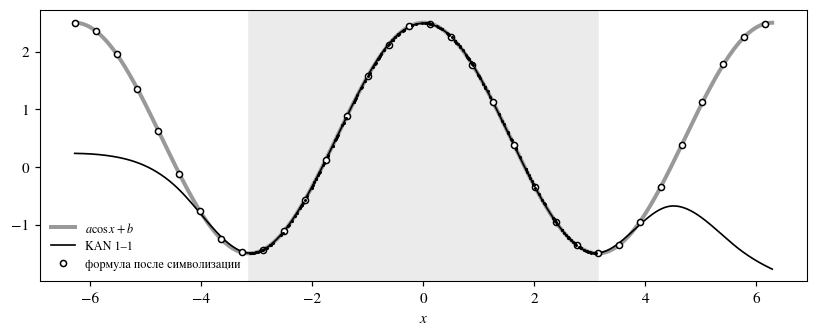

при π < |x| < 2π:  макс. ошибка сети = 4.27,  формулы = 3.3e-03


In [8]:
x_out = np.linspace(-2 * np.pi, 2 * np.pi, 2001)
y_kan = net1.forward((x_out / np.pi)[:, None])[:, 0]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.axvspan(-np.pi, np.pi, color=GREY, zorder=0)
ax.plot(x_out, f1(x_out), '-', color='0.6', lw=2.6, label=r'$a\cos x+b$')
ax.plot(x_out, y_kan, 'k-', lw=1.1, label='KAN 1–1')
ax.plot(x_out[::60], sym1(x_out)[::60], 'o', mfc='white', mec='black', ms=4, label='формула после символизации')
ax.plot(x_tr, y_tr1, '.', color='black', ms=2)
ax.set_xlabel('$x$'); ax.legend(fontsize=8, loc='lower left'); plt.show()
out = np.abs(x_out) > np.pi
print(f'при π < |x| < 2π:  макс. ошибка сети = {np.max(np.abs(y_kan - f1(x_out))[out]):.2f},'
      f'  формулы = {np.max(np.abs(sym1(x_out) - f1(x_out))[out]):.1e}')

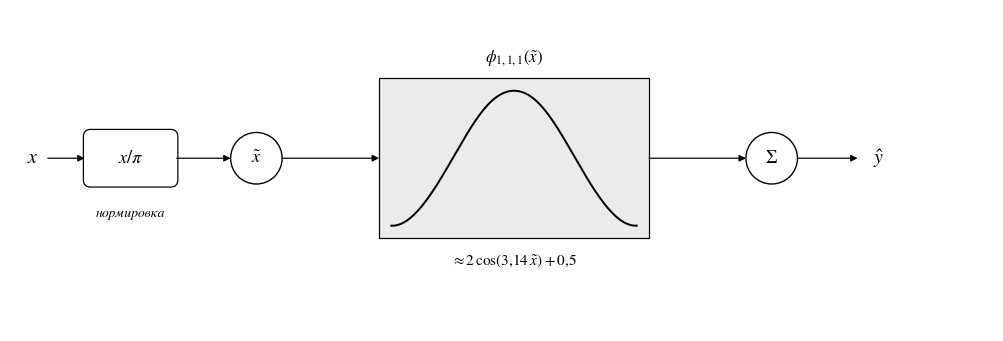

In [9]:
fig = plt.figure(figsize=(9, 2.9))
ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 16); ax.set_ylim(0, 5.2); ax.set_aspect('equal'); ax.axis('off')
ax.text(0.35, 2.8, '$x$', ha='center', va='center', fontsize=13); _arrow(ax, 0.6, 2.8, 1.2, 2.8)
ax.add_patch(FancyBboxPatch((1.2, 2.35), 1.5, 0.9, boxstyle='round,pad=0.02,rounding_size=0.12', fc='white', ec='black', lw=0.8))
ax.text(1.95, 2.8, r'$x/\pi$', ha='center', va='center', fontsize=12)
ax.text(1.95, 1.85, 'нормировка', ha='center', fontsize=9, style='italic')
_node(ax, 4.0, 2.8, r'$\tilde x$'); _arrow(ax, 2.7, 2.8, 3.58, 2.8)
_edge(ax, 8.2, 2.8, zs, L.edge(0, 0, zs), r'$\phi_{1,1,1}(\tilde x)$',
      rf'$\approx {mnum(al, 3)}\,\cos({mnum(be, 3)}\,\tilde x){signed(et)}$', w=4.4, h=2.6)
_arrow(ax, 4.42, 2.8, 6.0, 2.8)
_node(ax, 12.4, 2.8, r'$\Sigma$'); _arrow(ax, 10.4, 2.8, 11.98, 2.8); _arrow(ax, 12.82, 2.8, 13.8, 2.8)
ax.text(14.05, 2.8, r'$\hat y$', va='center', fontsize=13)
plt.show()

**Выводы по примеру 1.**
1. Сеть с одной связью точно аппроксимирует функцию внутри отрезка обучения, но её обучение — линейный МНК; итерации и «нейросеть» здесь избыточны.
2. Вне отрезка сеть ошибается сильно: сплайны финитны, и остаётся только базовая функция SiLU.
3. Если вид функции заранее известен, $a$ и $b$ можно найти МНК прямо по данным. Символизация ценна, только когда вид функции **неизвестен** — тогда библиотека и таблица $R^2$ подсказывают его.

<a id="ex2"></a>
## 3. Пример 2. $f(x,y)=\exp(\sin\pi x+y^2)$: когда нужны KAN и итерации

Функция — суперпозиция ровно того вида, что в теореме Колмогорова–Арнольда: внутренние функции $\sin\pi x$ и $y^2$ складываются, а сумма проходит через внешнюю функцию $\exp$. Обучаемся на квадрате $[-1,1]^2$ по 500 случайным точкам.

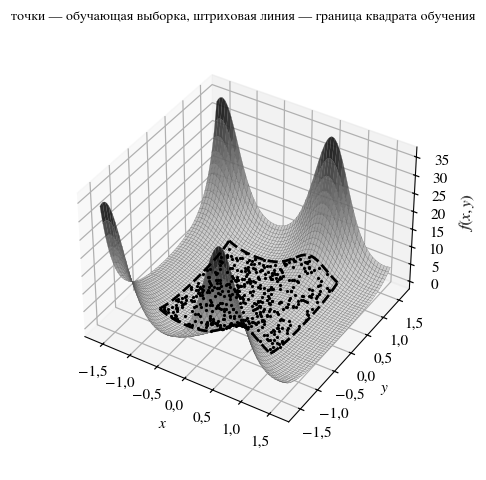

In [10]:
f2 = lambda x, y: np.exp(np.sin(np.pi * x) + y ** 2)
rng = np.random.default_rng(11)
def make(n):
    X = rng.uniform(-1, 1, (n, 2))
    return X, f2(X[:, 0], X[:, 1])[:, None]
X_tr, y_tr = make(500); X_va, y_va = make(100); X_te, y_te = make(1000)

R_OUT = 1.6
gs = np.linspace(-R_OUT, R_OUT, 121); SX, SY = np.meshgrid(gs, gs); SZ = f2(SX, SY)
fig = plt.figure(figsize=(7, 5.2))
ax = fig.add_subplot(111, projection='3d', computed_zorder=False)
ax.plot_surface(SX, SY, SZ, cmap='Greys', vmin=-0.3 * SZ.max(), vmax=SZ.max(), rstride=2, cstride=2,
                linewidth=0.15, edgecolor='0.35', alpha=0.9, zorder=1)
s = np.linspace(-1, 1, 200)
for xs_, ys_ in [(s, -np.ones_like(s)), (s, np.ones_like(s)), (-np.ones_like(s), s), (np.ones_like(s), s)]:
    ax.plot(xs_, ys_, f2(xs_, ys_) + 0.05, color='black', lw=1.8, ls='--', zorder=10)
ax.scatter(X_tr[:, 0], X_tr[:, 1], y_tr[:, 0] + 0.05, s=1.2, color='black', depthshade=False, zorder=11)
ax.set_xlabel('$x$'); ax.set_ylabel('$y$'); ax.set_zlabel('$f(x,y)$'); ax.view_init(elev=38, azim=-58); ax.set_box_aspect(None, zoom=0.85)
ax.set_title('точки — обучающая выборка, штриховая линия — граница квадрата обучения', fontsize=9)
plt.show()

Внутри квадрата обучения функция спокойная (от 0,4 до 7), а сразу за его границей по $y$ начинается резкий рост: множитель $e^{y^2}$ даёт пики до 35. Данные об этом росте ничего не сообщают — это пригодится при обсуждении экстраполяции.

### 3.1. Линейные модели: одна операция МНК

In [11]:
t10 = knots(-1, 1, 10, 3)
V_add = lambda X: np.hstack([np.ones((len(X), 1)), bspline(X[:, 0], t10, 3), bspline(X[:, 1], t10, 3)])
c_add = np.linalg.lstsq(V_add(X_tr), y_tr, rcond=None)[0]
res_add = rmse(V_add(X_te) @ c_add, y_te)

t5 = knots(-1, 1, 5, 3)
def V_tensor(X):
    B1, B2 = bspline(X[:, 0], t5, 3), bspline(X[:, 1], t5, 3)
    return (B1[:, :, None] * B2[:, None, :]).reshape(len(X), -1)
c_ten = np.linalg.lstsq(V_tensor(X_tr), y_tr, rcond=None)[0]
res_ten = rmse(V_tensor(X_te) @ c_ten, y_te)
print(f'аддитивная модель g(x)+h(y):  {V_add(X_tr).shape[1]} параметров, RMSE = {res_add:.4f}')
print(f'двумерный (тензорный) сплайн: {V_tensor(X_tr).shape[1]} параметра, RMSE = {res_ten:.4f}')

аддитивная модель g(x)+h(y):  27 параметров, RMSE = 0.4079
двумерный (тензорный) сплайн: 64 параметра, RMSE = 0.0667


* **Аддитивная модель** не справляется принципиально: $f$ содержит взаимодействие переменных, а смешанная разность аддитивной модели равна нулю (п. 4.2.2).
* **Двумерный сплайн** справился бы при большом числе параметров, но оно растёт как квадрат числа узлов — проклятие размерности (4.10) — и структуру функции он не видит.

### 3.2. Сеть 2–1–1: нелинейная задача, нужны итерации

Выход сети $\hat f=\phi_{2,1,1}\big(\phi_{1,1,1}(x)+\phi_{1,1,2}(y)\big)$ **нелинеен** по коэффициентам первого слоя: они стоят внутри функции второго слоя. Одной операцией $V\backslash y$ эту задачу не решить — нужен итерационный метод (Adam, глава 5). Обучаем на сетке $G=5$, затем уточняем сетку до $G=10$ по формуле (4.27).

время обучения: 12.0 с



| Модель | Параметров | Способ | RMSE на тесте |
|---|---|---|---|
| аддитивная $g(x)+h(y)$ | 27 | один МНК | 0,408 |
| двумерный сплайн | 64 | один МНК | 0,0667 |
| **KAN 2–1–1, $G=5$** | **30** | Adam, 2000 эпох | **0,00758** |
| **KAN 2–1–1, $G=5\to10$** | **45** | Adam, ещё 2000 эпох | **0,000471** |


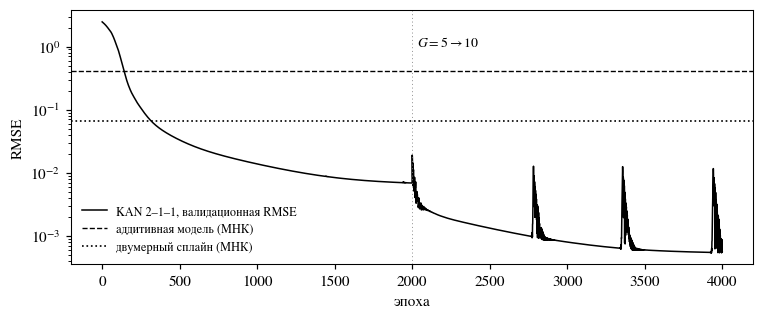

In [12]:
net2 = KAN([2, 1, 1], G=5)
r = np.random.default_rng(1)
for Ly in net2.layers:
    Ly.c[...] = r.normal(0, 0.1, Ly.c.shape)
    Ly.wb[...] = r.normal(0, 1 / np.sqrt(Ly.nin), Ly.wb.shape)
hist2 = []; t0 = time.perf_counter()
train(net2, X_tr, y_tr, X_va, y_va, 2000, 0.01, hist2)
res_k5, p5 = rmse(net2.forward(X_te), y_te), net2.n_params()
net2.update_grid(X_tr, 10)
train(net2, X_tr, y_tr, X_va, y_va, 2000, 0.003, hist2)
res_k10, p10 = rmse(net2.forward(X_te), y_te), net2.n_params()
print(f'время обучения: {time.perf_counter() - t0:.1f} с')

display(Markdown(f'''
| Модель | Параметров | Способ | RMSE на тесте |
|---|---|---|---|
| аддитивная $g(x)+h(y)$ | 27 | один МНК | {num(res_add, 3)} |
| двумерный сплайн | 64 | один МНК | {num(res_ten, 3)} |
| **KAN 2–1–1, $G=5$** | **{p5}** | Adam, 2000 эпох | **{num(res_k5, 3)}** |
| **KAN 2–1–1, $G=5\\to10$** | **{p10}** | Adam, ещё 2000 эпох | **{num(res_k10, 3)}** |
'''))

fig, ax = plt.subplots(figsize=(8, 3))
ax.semilogy(np.sqrt(np.array(hist2)[:, 1]), 'k-', lw=1, label='KAN 2–1–1, валидационная RMSE')
ax.axhline(res_add, color='black', ls='--', lw=0.9, label='аддитивная модель (МНК)')
ax.axhline(res_ten, color='black', ls=':', lw=1.1, label='двумерный сплайн (МНК)')
ax.axvline(2000, color='0.5', lw=0.6, ls=(0, (1, 3))); ax.text(2030, 1.0, r'$G=5\to10$', fontsize=9)
ax.set_xlabel('эпоха'); ax.set_ylabel('RMSE'); ax.legend(fontsize=8); plt.show()

Уже через несколько сотен эпох сеть опускается ниже обеих МНК-моделей, хотя параметров у неё меньше, чем у двумерного сплайна.

### 3.3. Символизация: сеть подсказывает, какие функции стоят на связях

На этот раз ответ заранее не задан: для каждой связи перебирается вся библиотека, и выбирается функция с наибольшим $R^2$. При почти равных $R^2$ берётся функция с меньшим числом подбираемых нелинейных параметров.

In [13]:
L1, L2 = net2.layers
z = np.linspace(-1, 1, 401)
h_tr = L1.forward(X_tr)[:, 0]
H = np.linspace(h_tr.min(), h_tr.max(), 401)
edges = {r'$\phi_{1,1,1}(x)$': (z, L1.edge(0, 0, z)),
         r'$\phi_{1,1,2}(y)$': (z, L1.edge(0, 1, z)),
         r'$\phi_{2,1,1}(h)$': (H, L2.edge(0, 0, H))}
tabs = {name: symbolize(*e) for name, e in edges.items()}
display(Markdown(r2_table(tabs)))
found = {name: tab[choose(tab)][1] for name, tab in tabs.items()}
(al1, b1, g1, e1), (al2, _, _, e2), (al3, b3, _, e3) = found.values()

| Связь | z | z² | z³ | tanh(βz) | exp(βz) | sin(βz+γ) | выбрано |
|---|---|---|---|---|---|---|---|
| $\phi_{1,1,1}(x)$ | 0,60337270 | 0,00000000 | 0,21426484 | 0,86855454 | 0,60337268 | **0,99999964** | sin(βz+γ) |
| $\phi_{1,1,2}(y)$ | 0,00000000 | **0,99999998** | 0,00000000 | 0,00000000 | 0,33814047 | 0,99999976 | z² |
| $\phi_{2,1,1}(h)$ | 0,87884240 | 0,05567385 | 0,75408672 | 0,87870286 | **1,00000000** | 0,99286208 | exp(βz) |


Обратите внимание на вторую строку: синус с подобранными частотой и фазой приближает параболу почти так же хорошо, как $y^2$. Сеть восстанавливает **форму** кривой; выбор между близкими записями — правило, которое задаёт человек.

**Проверка структуры.** Если $f=\exp(\sin\pi x+y^2)$ точно представлена сетью 2–1–1, то по рассуждению примера 4.6 функции первого слоя совпадают с $\sin\pi x$ и $y^2$ с точностью до *общего* множителя, а показатель внешней экспоненты обратен этому множителю:


| Величина | Найдено | Теория |
|---|---|---|
| частота синуса $\beta$ | 3,1425 | $\pi\approx 3{,}1416$ |
| $\alpha_{\sin}/\alpha_{y^2}$ | 1,0001 | 1 |
| $\beta_{\exp}\cdot\alpha_{\sin}$ | 1,0001 | 1 |


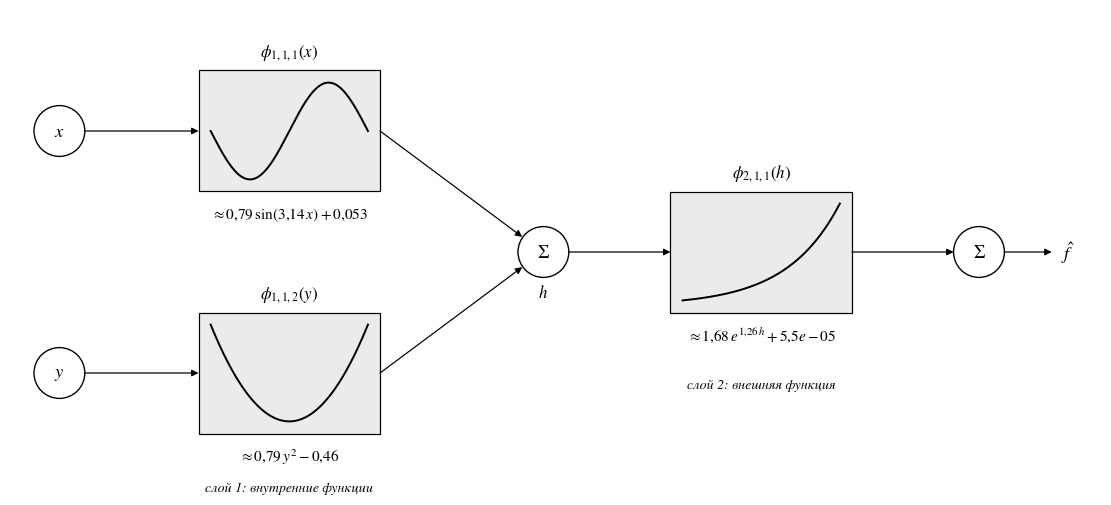

In [14]:
display(Markdown(f'''
| Величина | Найдено | Теория |
|---|---|---|
| частота синуса $\\beta$ | {fx(b1)} | $\\pi\\approx 3{{,}}1416$ |
| $\\alpha_{{\\sin}}/\\alpha_{{y^2}}$ | {fx(al1 / al2)} | 1 |
| $\\beta_{{\\exp}}\\cdot\\alpha_{{\\sin}}$ | {fx(b3 * al1)} | 1 |
'''))

fig = plt.figure(figsize=(10, 4.4))
ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 18); ax.set_ylim(0, 8); ax.set_aspect('equal'); ax.axis('off')
_node(ax, 0.8, 6.0, '$x$'); _node(ax, 0.8, 2.0, '$y$')
(z1, p1), (z2, p2), (z3, p3) = edges.values()
_edge(ax, 4.6, 6.0, z1, p1, r'$\phi_{1,1,1}(x)$', rf'$\approx {mnum(al1, 2)}\,\sin({mnum(b1, 3)}\,x){signed(e1)}$')
_edge(ax, 4.6, 2.0, z2, p2, r'$\phi_{1,1,2}(y)$', rf'$\approx {mnum(al2, 2)}\,y^2{signed(e2)}$')
_arrow(ax, 1.22, 6.0, 3.1, 6.0); _arrow(ax, 1.22, 2.0, 3.1, 2.0)
_node(ax, 8.8, 4.0, r'$\Sigma$'); ax.text(8.8, 3.25, '$h$', ha='center', fontsize=11)
_arrow(ax, 6.1, 6.0, 8.45, 4.25); _arrow(ax, 6.1, 2.0, 8.45, 3.75)
_edge(ax, 12.4, 4.0, z3, p3, r'$\phi_{2,1,1}(h)$', rf'$\approx {mnum(al3, 3)}\,e^{{{mnum(b3, 3)}\,h}}{signed(e3)}$')
_arrow(ax, 9.22, 4.0, 10.9, 4.0)
_node(ax, 16.0, 4.0, r'$\Sigma$'); _arrow(ax, 13.9, 4.0, 15.58, 4.0); _arrow(ax, 16.42, 4.0, 17.2, 4.0)
ax.text(17.35, 4.0, r'$\hat f$', va='center', fontsize=12)
ax.text(4.6, 0.05, 'слой 1: внутренние функции', ha='center', fontsize=9, style='italic')
ax.text(12.4, 1.75, 'слой 2: внешняя функция', ha='center', fontsize=9, style='italic')
plt.show()

### 3.4. Экстраполяция: что происходит за пределами квадрата

Сравним четыре модели на квадрате $[-1{,}6;\,1{,}6]^2$:
* KAN, у которой сплайны вне сетки равны нулю (как в главе);
* та же сеть с **линейным продолжением** функций на связях по касательной;
* двумерный сплайн (МНК);
* формула, восстановленная символизацией: $\hat f=\alpha_3\exp\big(\beta_3(\alpha_1\sin(\beta_1x+\gamma_1)+\eta_1+\alpha_2y^2+\eta_2)\big)+\eta_3$.

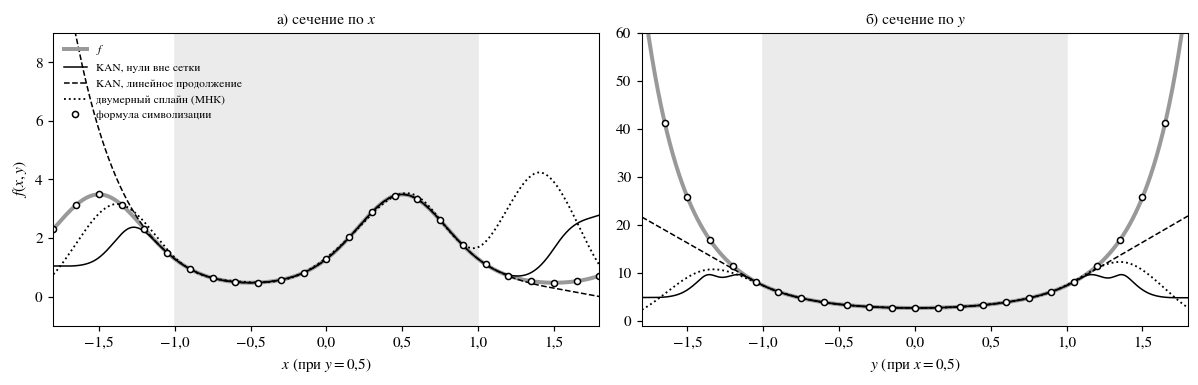

In [15]:
def f_sym(X):
    h = al1 * np.sin(b1 * X[:, 0] + g1) + e1 + al2 * X[:, 1] ** 2 + e2
    return al3 * np.exp(b3 * h) + e3

def kan_pred(X, mode):
    net2.set_extension(mode); out = net2.predict(X)[:, 0]; net2.set_extension('zero'); return out

models = [('KAN, нули вне сетки',        lambda X: kan_pred(X, 'zero'),   dict(color='black', ls='-', lw=1.0)),
          ('KAN, линейное продолжение',  lambda X: kan_pred(X, 'linear'), dict(color='black', ls='--', lw=1.0)),
          ('двумерный сплайн (МНК)',     lambda X: (V_tensor(X) @ c_ten)[:, 0], dict(color='black', ls=':', lw=1.2)),
          ('формула символизации',       f_sym, None)]

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, lab, mk in [(axs[0], r'$x$ (при $y=0{,}5$)', lambda s: np.stack([s, np.full_like(s, 0.5)], 1)),
                    (axs[1], r'$y$ (при $x=0{,}5$)', lambda s: np.stack([np.full_like(s, 0.5), s], 1))]:
    s = np.linspace(-1.8, 1.8, 721); X = mk(s)
    ax.axvspan(-1, 1, color=GREY, zorder=0)
    ax.plot(s, f2(X[:, 0], X[:, 1]), '-', color='0.6', lw=2.6, label='$f$')
    for name, pred, st in models:
        if st is None: ax.plot(s[::30], pred(X)[::30], 'o', mfc='white', mec='black', ms=4, label=name)
        else: ax.plot(s, pred(X), label=name, **st)
    ax.set_xlabel(lab); ax.set_xlim(s[0], s[-1])
axs[0].set_ylim(-1, 9); axs[1].set_ylim(-1, 60); axs[0].set_ylabel('$f(x,y)$')
axs[0].set_title('а) сечение по $x$', fontsize=10); axs[1].set_title('б) сечение по $y$', fontsize=10)
axs[0].legend(fontsize=7.5, loc='upper left'); fig.tight_layout(); plt.show()

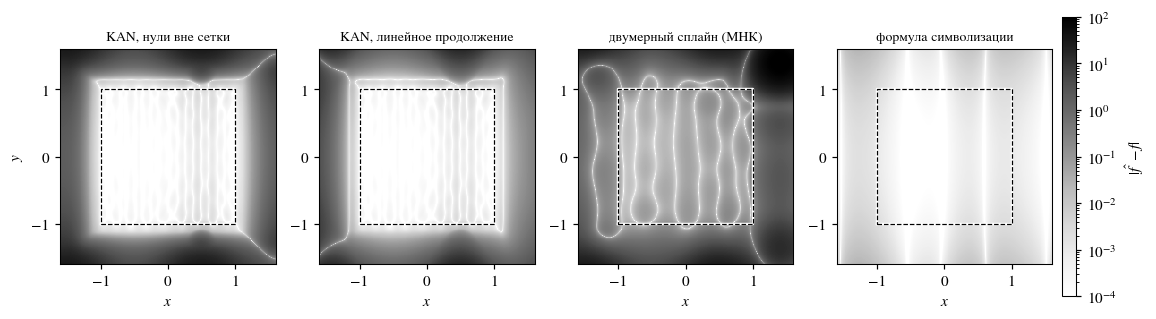

| Модель | Макс. ошибка внутри | Макс. ошибка снаружи | Относит. ошибка снаружи |
|---|---|---|---|
| KAN, нули вне сетки | 0,0054 | 33 | 363 % |
| KAN, линейное продолжение | 0,0054 | 17 | 131 % |
| двумерный сплайн (МНК) | 4,2 | 1,2e+02 | 5235 % |
| формула символизации | 0,0026 | 0,026 | 0,1 % |


In [16]:
g = np.linspace(-R_OUT, R_OUT, 241); GX, GY = np.meshgrid(g, g)
Xg = np.stack([GX.ravel(), GY.ravel()], axis=1); Fg = f2(Xg[:, 0], Xg[:, 1])
ring = np.max(np.abs(Xg), axis=1) > 1

fig, axs = plt.subplots(1, 4, figsize=(12, 3.3))
rows = ''
for ax, (name, pred, _) in zip(axs, models):
    e = np.abs(pred(Xg) - Fg)
    rows += f'| {name} | {num(e[~ring].max(), 2)} | {num(e[ring].max(), 2)} | {pct(100 * np.max(e[ring] / Fg[ring]))} |\n'
    im = ax.pcolormesh(GX, GY, np.clip(e.reshape(GX.shape), 1e-4, 1e2), cmap='Greys', norm=LogNorm(1e-4, 1e2), shading='auto')
    ax.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], color='white', lw=1.6)
    ax.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], color='black', lw=0.8, ls='--')
    ax.set_aspect('equal'); ax.set_title(name, fontsize=9); ax.set_xlabel('$x$')
    ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1])
axs[0].set_ylabel('$y$')
fig.colorbar(im, ax=axs, fraction=0.02, pad=0.01).set_label(r'$|\hat f-f|$')
plt.show()
display(Markdown('| Модель | Макс. ошибка внутри | Макс. ошибка снаружи | Относит. ошибка снаружи |\n|---|---|---|---|\n' + rows))

**Выводы по примеру 2.**
1. Обученные модели экстраполируют плохо. Линейное продолжение функций на связях снижает ошибку, но не решает проблему: $e^{y^2}$ не продолжается линейно.
2. Формула, извлечённая из сети, продолжает функцию правильно, потому что содержит настоящие $\sin$, $y^2$ и $\exp$.
3. Здесь формула оказалась точнее сети даже **внутри** квадрата. Так получилось только потому, что $f$ в точности составлена из функций библиотеки, а коэффициенты уточнены мелким перебором (их можно уточнить и нелинейным МНК (3.36) из главы 3). Для зависимости без простой формулы картина обратная: сеть точнее, а формула даёт систематическую ошибку.

<a id="summary"></a>
## 4. Итог: что даёт сеть, а что — формула

Символизация — не конкурирующий метод, а последний шаг работы с обученной сетью: она «читает» функции на связях.

| | Обученная KAN | Формула после символизации |
|---|---|---|
| Точность внутри области обучения | высокая, регулируется числом узлов $G$ | ограничена выбором вида функции и подбором коэффициентов |
| Если нужной функции нет в библиотеке | работает как обычно | даёт систематическую ошибку |
| Зависимость от решений человека | нет | библиотека, правило выбора при близких $R^2$ |
| Шумные данные | грубая сетка сглаживает шум | выбор формулы становится неоднозначным |
| Экстраполяция | плохая, требует контроля диапазона | правильная, **если формула верна** |
| Интерпретация и проверка по размерностям | затруднена | естественна |

Главное преимущество KAN по сравнению с прямым поиском формулы по данным: **структуру суперпозиции находит градиентное обучение**, а вид каждой функции подбирается отдельно, как одномерная задача. Без сети пришлось бы перебирать и структуры, и функции одновременно.

Разумная инженерная схема: использовать сеть внутри проверенного диапазона, а формулу — как гипотезу о законе, которую нужно подтвердить на независимых данных.